# Where should the support floor sit, and what is a strip slot worth in rupees?

**Week 4, Wednesday, chapter 3 of 3.** The pairs table ranks every pair the strip could
suggest. Three slots are available. Which three pairs fill them, and what does each slot
earn in rupees a month.

**Who needs the answer.** The growth lead, who must defend the number against finance.

**The questions on the way.** Where does the support floor sit, how do we read lift and
support together, and what is the margin a slot earns net of the discount a cart returns.

**Setup.** Load the 40,000 Pune carts and their items. Rebuild the marginals and the
pair counts from the plain pandas functions the chapter 2 notebook used, so the rupee
model that follows reads from the same ground.

In [1]:
import sys, pathlib
here = pathlib.Path.cwd()
for parent in [here, *here.parents]:
    if (parent / "scripts" / "c2kit.py").exists():
        sys.path.insert(0, str(parent / "scripts")); break
import c2kit as kit

import pandas as pd
from collections import Counter
from itertools import combinations
carts = pd.read_csv("../data/C2_W04_D03_carts_STUDENT.csv")
items = pd.read_csv("../data/C2_W04_D03_cart_items_STUDENT.csv")
n = len(carts)
baskets = items.groupby("cart_id")["item"].apply(set)
marg = items.groupby("item").cart_id.nunique() / n
pair_counts = Counter()
for s in baskets:
    for a, b in combinations(sorted(s), 2):
        pair_counts[(a, b)] += 1
print(f"loaded {n:,} carts, {len(marg)} items, {len(pair_counts):,} distinct pairs")

loaded 40,000 carts, 14 items, 91 distinct pairs


## The map of where this notebook sits in the day

Chapter 1 and 2 built the pairs table. This chapter asks what each slot earns.

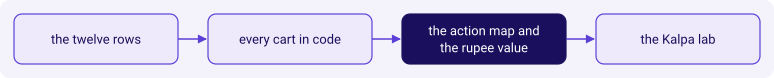

In [2]:
kit.flow(["the twelve rows",
          "every cart in code",
          "the action map and the rupee value",
          "the Kalpa lab"],
         lit=2, show=True)

## The action map, drawn as code

For every pair, record its support and its lift. The four regions follow from a support
floor at 1 percent and a lift of 1: a pair above the floor and well above 1 goes to the
strip; above 1 and below the floor goes to a watch list; near 1 is independence; and the
high confidence to a popular partner that reads near 1 is the trap.

**Predict before you run.** How many pairs sit above the 1 percent floor and above a lift
of 2?

In [3]:
rows = []
for (a, b), count in pair_counts.items():
    s = count / n
    lift = s / (marg[a] * marg[b])
    rows.append((a, b, count, s, lift))
pairs = pd.DataFrame(rows, columns=["a", "b", "count", "support", "lift"])
above_floor = pairs[pairs.support >= 0.01]
promote_candidates = above_floor[above_floor.lift >= 2.0].sort_values("lift", ascending=False)
watch_candidates = pairs[(pairs.support < 0.01) & (pairs.lift >= 2.0)].sort_values("lift", ascending=False)
print(f"pairs above 1 percent support:        {len(above_floor):,}")
print(f"of those, with lift at least 2:        {len(promote_candidates):,}")
print(f"pairs below the floor with lift >=2:   {len(watch_candidates):,}")
print()
print("top five promote candidates by lift:")
print(promote_candidates.head(5).to_string(index=False))
kit.check("there is at least one promote candidate",   len(promote_candidates) >= 1)
kit.check("chips/cold is a promote candidate",
          any(sorted((r.a, r.b)) == sorted(("chips", "cold drink"))
              for _, r in promote_candidates.iterrows()))

pairs above 1 percent support:        70
of those, with lift at least 2:        1
pairs below the floor with lift >=2:   1

top five promote candidates by lift:
    a          b  count  support     lift
chips cold drink   1999 0.049975 3.322298


## The map on one picture

Plot every pair with a support of at least 0.1 percent on lift against support, with the
floor as a vertical line.

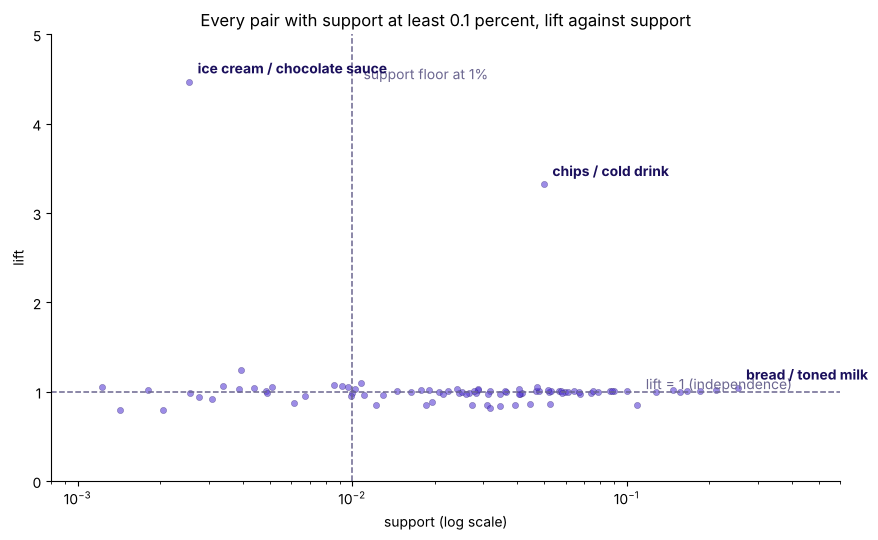

In [4]:
import matplotlib.pyplot as plt
plot_pairs = pairs[pairs.support >= 0.001]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(plot_pairs.support, plot_pairs.lift, s=20, color="#5B3FD6", alpha=0.6,
           edgecolor="#1A0F5C", linewidth=0.3)
ax.axhline(1.0, color="#6B6690", lw=1.1, ls="--")
ax.axvline(0.01, color="#6B6690", lw=1.1, ls="--")
ax.text(0.011, 4.5, "support floor at 1%", color="#6B6690", fontsize=10)
ax.text(0.4, 1.03, "lift = 1 (independence)", color="#6B6690", fontsize=10, ha="right")
# Label the four pairs the room will discuss.
for a, b in [("chips", "cold drink"), ("ice cream", "chocolate sauce"),
             ("bread", "toned milk")]:
    row = plot_pairs[((plot_pairs.a == a) & (plot_pairs.b == b)) |
                     ((plot_pairs.a == b) & (plot_pairs.b == a))]
    if len(row):
        s, l = row.support.iloc[0], row.lift.iloc[0]
        ax.annotate(f"{a} / {b}", (s, l), textcoords="offset points",
                    xytext=(6, 6), color="#1A0F5C", fontsize=10, weight="bold")
ax.set_xscale("log")
ax.set_xlim(0.0008, 0.6)
ax.set_ylim(0, 5)
ax.set_xlabel("support (log scale)")
ax.set_ylabel("lift")
ax.set_title("Every pair with support at least 0.1 percent, lift against support")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()

## What a slot earns, line by line

Build the slot's value from the four assumptions the ticket allows: 60,000 cart-page views
a day in Pune, half the clicks turn into an add, Rs 9 margin per added item, and the
slot's click-through rate decides how many clicks it earns.

**Predict before you run.** A slot full of milk suggestions clicks at 1.2 percent. A slot
showing a chance-beating pair clicks at 6.4 percent. The margin gap in rupees a month
across three slots is nearest to:

- a) Rs 50,000
- b) Rs 2 lakh
- c) Rs 12 lakh
- d) Rs 50 lakh

In [5]:
views_a_day = 60_000
add_rate = 0.5
margin_per_add_rs = 9
milk_ctr = 0.012
other_ctr = 0.064
def slot_value(ctr):
    return views_a_day * ctr * add_rate * margin_per_add_rs
milk_value = slot_value(milk_ctr)
other_value = slot_value(other_ctr)
gap_per_slot_month = (other_value - milk_value) * 30
three_slots_month = gap_per_slot_month * 3
print(f"a milk-slot earns  Rs {milk_value:,.0f} a day")
print(f"a chance-beating slot earns Rs {other_value:,.0f} a day")
print(f"gap per slot per month      Rs {gap_per_slot_month:,.0f}")
print(f"across three slots per month Rs {three_slots_month:,.0f}  (~ Rs {three_slots_month/100000:.1f} lakh)")
kit.check("milk slot earns Rs 3,240 a day",      round(milk_value) == 3240)
kit.check("other slot earns Rs 17,280 a day",    round(other_value) == 17280)
kit.check("three slots earn Rs 12.6 lakh/month", abs(three_slots_month - 1_263_600) < 1000)

a milk-slot earns  Rs 3,240 a day
a chance-beating slot earns Rs 17,280 a day
gap per slot per month      Rs 421,200
across three slots per month Rs 1,263,600  (~ Rs 12.6 lakh)


**What happened.** The answer is c. The gap across three slots lands near Rs 12.6 lakh a
month, with every assumption labelled and a range sitting beside each one. The number
the growth lead carries to Friday is this gap, with the two slot click-throughs beside
it as the evidence.

## The caveat the fallback picks up: the heavy tenth

The top ten percent of customers place 38 percent of the carts. If chips and cold drink
is driven by a small set of party shoppers, a recomputation per customer rather than per
cart will drop its lift. Milk's lift, computed per customer, should move very little
because milk is bought by nearly everyone.

In [6]:
customer_items = items.merge(carts[["cart_id", "customer_id"]], on="cart_id")
cust_sets = customer_items.groupby("customer_id")["item"].apply(set)
n_cust = len(cust_sets)
def pair_per_customer(a, b):
    joint = sum(1 for s in cust_sets if a in s and b in s)
    pa = sum(1 for s in cust_sets if a in s) / n_cust
    pb = sum(1 for s in cust_sets if b in s) / n_cust
    sup = joint / n_cust
    return sup, sup / (pa * pb) if pa > 0 and pb > 0 else 0
sup_cc_cust, lift_cc_cust = pair_per_customer("chips", "cold drink")
sup_bm_cust, lift_bm_cust = pair_per_customer("bread", "toned milk")
print(f"per cart (from above):     chips/cold lift 3.32, bread/milk lift 1.04")
print(f"per customer:              chips/cold lift {lift_cc_cust:.2f}, bread/milk lift {lift_bm_cust:.2f}")
kit.check("bread/milk per-customer lift stays near 1", abs(lift_bm_cust - 1.0) < 0.2)

per cart (from above):     chips/cold lift 3.32, bread/milk lift 1.04
per customer:              chips/cold lift 1.74, bread/milk lift 1.04


**What happened.** Chips and cold drink's lift drops under the per-customer denominator;
bread and milk's lift stays near one. The pair's strength is partly a heavy-shopper
pattern, which the caveat makes visible. The strip can still carry chips and cold drink,
and the growth lead carries the caveat as the fact that would change the call.

## The map after today

Today earns the strip the three slots and the rupee value. Thursday asks the same shape
on who is leaving, where a flat retention rate hides falling cohorts.

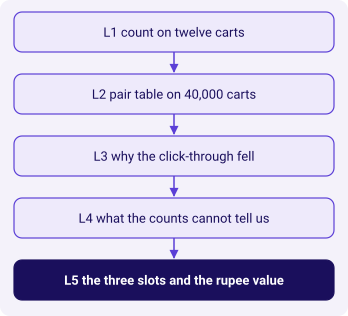

In [7]:
kit.vflow(["L1 count on twelve carts",
           "L2 pair table on 40,000 carts",
           "L3 why the click-through fell",
           "L4 what the counts cannot tell us",
           "L5 the three slots and the rupee value"],
          lit=4, show=True)

In [8]:
kit.check_summary()